In [2]:
# %pip install pandas numpy openpyxl matplotlib seaborn scikit-learn

In [3]:
import pandas as pd
import numpy as np
print(" Our Libraries are ready!")

 Our Libraries are ready!


In [4]:
import openpyxl
print("Excel reader is ready!")

Excel reader is ready!


In [5]:
import pandas as pd 
df = pd.read_excel(r"C:\Users\MY PC\Desktop\customer_behaviour_segmentation/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
df.shape

(541909, 8)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(5268)

In [10]:
print("Earliest date:", df["InvoiceDate"].min())
print("Latest date:", df["InvoiceDate"].max())

Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00


In [11]:
(df["Quantity"] <0).sum()

np.int64(10624)

In [12]:
(df["UnitPrice"] <0).sum()

np.int64(2)

In [13]:
(df["Quantity"] ==0).sum()

np.int64(0)

In [14]:
df[df["Quantity"] <0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [15]:
# Check cancellation records
negative_qty = df[df["Quantity"] < 0]

print("NEGATIVE QUANTITY CHECK")
print(negative_qty["InvoiceNo"].astype(str).str.startswith("C").value_counts())

# Inspect negative unit prices
print("\nNEGATIVE UNIT PRICE RECORDS")
display(df[df["UnitPrice"] < 0])

# Check zero unit prices
print("\nZERO UNIT PRICE COUNT")
print((df["UnitPrice"] == 0).sum())

NEGATIVE QUANTITY CHECK
InvoiceNo
True     9288
False    1336
Name: count, dtype: int64

NEGATIVE UNIT PRICE RECORDS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



ZERO UNIT PRICE COUNT
2515


In [16]:
# Create a copy of our original dataset
clean_df = df.copy()

# Remove exact duplicate records
clean_df = clean_df.drop_duplicates()

# Keep records with CustomerIDs
clean_df = clean_df.dropna(subset=["CustomerID"])

# Keep only positive quantities and unit prices
clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
]

# Calculate total sales for each row
clean_df["TotalAmount"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

# Display cleaning results
print("DATA CLEANING COMPLETED")
print("-----------------------")
print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))
print("Remaining missing CustomerIDs:", clean_df["CustomerID"].isna().sum())
print("Remaining duplicates:", clean_df.duplicated().sum())
print("Total sales value: £", round(clean_df["TotalAmount"].sum(), 2))

DATA CLEANING COMPLETED
-----------------------
Original rows: 541909
Cleaned rows: 392692
Rows removed: 149217
Remaining missing CustomerIDs: 0
Remaining duplicates: 0
Total sales value: £ 8887208.89


In [17]:
reference_date = clean_df["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)

Reference Date: 2011-12-10 12:50:00


In [18]:
rfm = clean_df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

rfm.rename(columns={
    "InvoiceDate": "Recency",
    "InvoiceNo": "Frequency",
    "TotalAmount": "Monetary"
}, inplace=True)

rfm = rfm.reset_index()

display(rfm.head(10))

C:\Users\MY PC\AppData\Local\Temp\ipykernel_11044\4290797419.py:7: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  rfm.rename(columns={


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40
5,12352.0,36,8,2506.04
6,12353.0,204,1,89.00
7,12354.0,232,1,1079.40
8,12355.0,214,1,459.40
9,12356.0,23,3,2811.43


In [19]:
print("TOTAL CUSTOMERS:", len(rfm))

display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

TOTAL CUSTOMERS: 4338


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


In [20]:
# Calculate percentile ranks
r_rank = rfm["Recency"].rank(pct=True)
f_rank = rfm["Frequency"].rank(pct=True)
m_rank = rfm["Monetary"].rank(pct=True)

# Assign scores from 1 to 5
bins = [0, 0.2, 0.4, 0.6, 0.8, 1]

rfm["R_Score"] = pd.cut(
    r_rank, bins=bins, labels=[5, 4, 3, 2, 1],
    include_lowest=True
).astype(int)

rfm["F_Score"] = pd.cut(
    f_rank, bins=bins, labels=[1, 2, 3, 4, 5],
    include_lowest=True
).astype(int)

rfm["M_Score"] = pd.cut(
    m_rank, bins=bins, labels=[1, 2, 3, 4, 5],
    include_lowest=True
).astype(int)

# Create combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

display(rfm.head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,1,77183.60,1,1,5,115
1,12347.0,2,7,4310.00,5,5,5,555
2,12348.0,75,4,1797.24,2,4,4,244
3,12349.0,19,1,1757.55,4,1,4,414
4,12350.0,310,1,334.40,1,1,2,112
5,12352.0,36,8,2506.04,3,5,5,355
6,12353.0,204,1,89.00,1,1,1,111
7,12354.0,232,1,1079.40,1,1,4,114
8,12355.0,214,1,459.40,1,1,2,112
9,12356.0,23,3,2811.43,4,3,5,435


In [21]:
conditions = [
    (rfm["R_Score"] >= 4) & (rfm["F_Score"] >= 4) & (rfm["M_Score"] >= 4),

    (rfm["R_Score"] >= 3) & (rfm["F_Score"] >= 4),

    (rfm["R_Score"] >= 4) & (rfm["F_Score"] >= 2),

    (rfm["R_Score"] <= 2) & (rfm["F_Score"] >= 3),

    (rfm["R_Score"] <= 2) & (rfm["F_Score"] <= 2)
]

labels = [
    "Champions",
    "Loyal Customers",
    "Potential Loyalists",
    "At-Risk Customers",
    "Hibernating Customers"
]

rfm["Segment"] = np.select(
    conditions,
    labels,
    default="Regular Customers"
)

# Count customers in each segment
segment_summary = (
    rfm["Segment"]
    .value_counts()
    .reset_index()
)

segment_summary.columns = ["Segment", "Customer Count"]

display(segment_summary)

,Segment,Customer Count
0,Hibernating Customers,966
1,Champions,902
2,Regular Customers,830
3,At-Risk Customers,772
4,Potential Loyalists,480
5,Loyal Customers,388


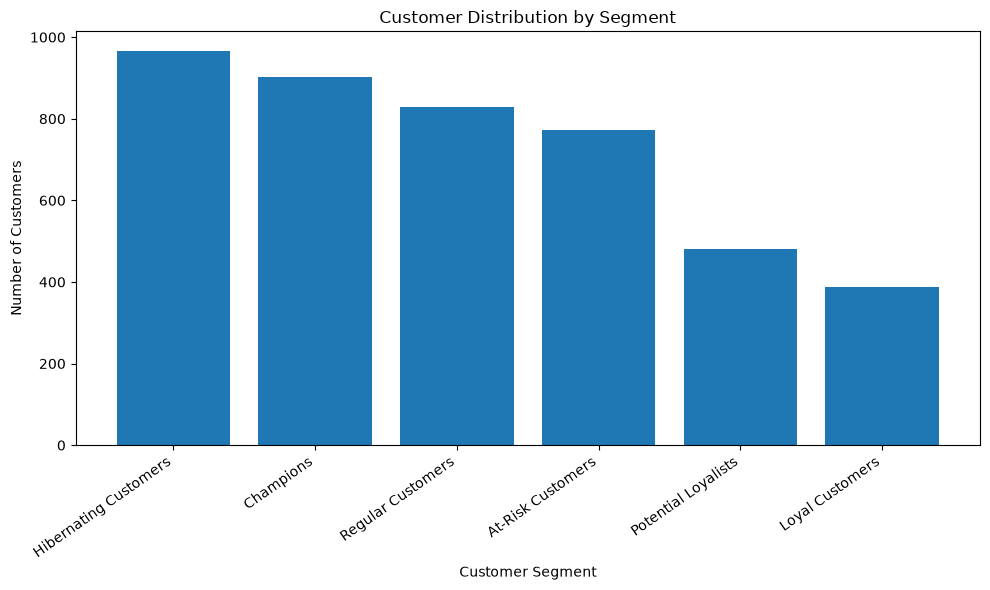

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    segment_summary["Segment"],
    segment_summary["Customer Count"]
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [23]:
segment_revenue = rfm.groupby("Segment")["Monetary"].sum().sort_values(ascending=False)

display(segment_revenue.round(2))

Segment
Champions                5648057.89
At-Risk Customers         929317.82
Loyal Customers           846757.42
Potential Loyalists       579216.93
Regular Customers         462331.68
Hibernating Customers     421527.15
Name: Monetary, dtype: float64

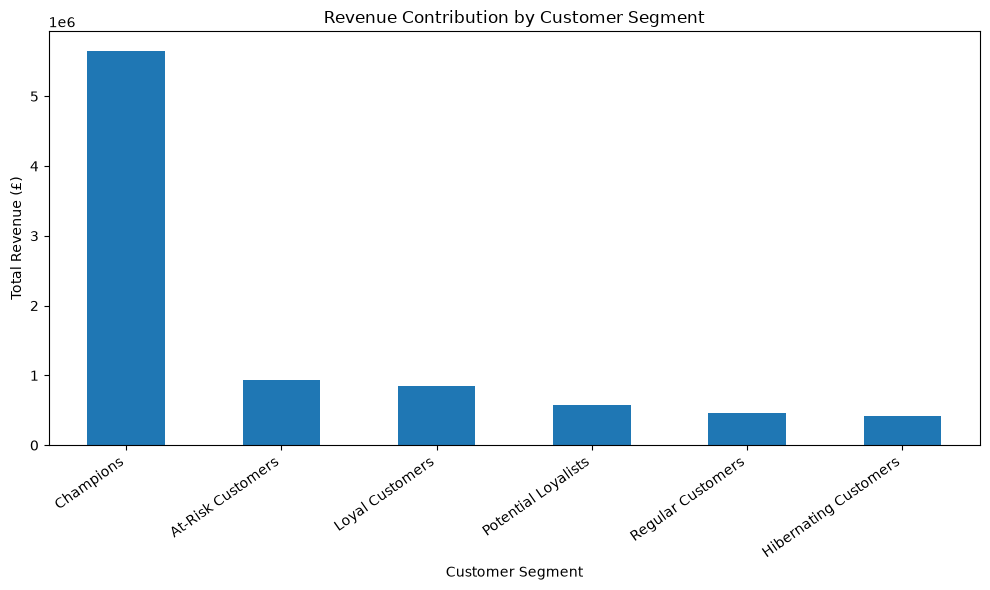

In [24]:
plt.figure(figsize=(10, 6))

segment_revenue.plot(kind="bar")

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

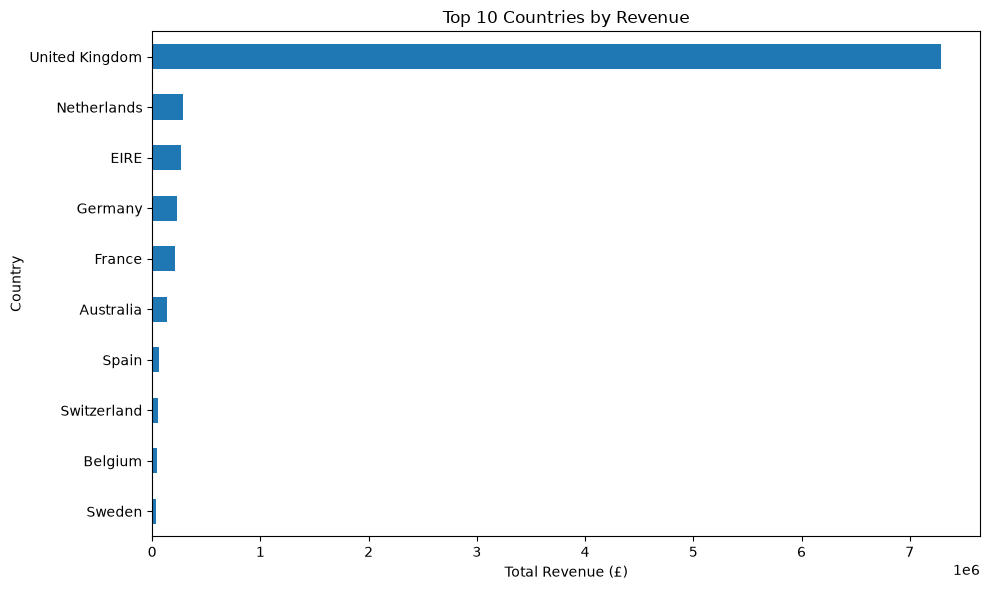

In [25]:
country_revenue = (
    clean_df.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
country_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

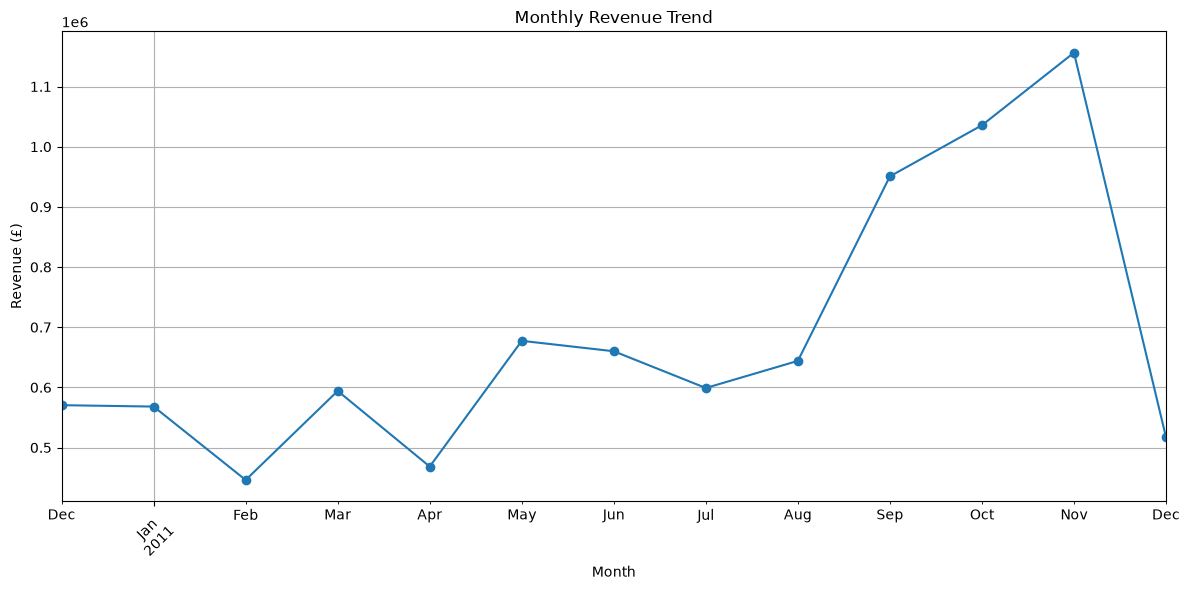

In [26]:
monthly_revenue = (
    clean_df.set_index("InvoiceDate")["TotalAmount"]
    .resample("ME")
    .sum()
)

plt.figure(figsize=(12, 6))

monthly_revenue.plot(marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
print("Highest revenue month:")
print(monthly_revenue.idxmax(), monthly_revenue.max())

print("\nLowest revenue month:")
print(monthly_revenue.idxmin(), monthly_revenue.min())

Highest revenue month:
2011-11-30 00:00:00 1156205.61

Lowest revenue month:
2011-02-28 00:00:00 446084.92


In [28]:
print("FINAL ANALYSIS VALIDATION")
print("-------------------------")

print("Total customers:", len(rfm))
print("Unique customer IDs:", rfm["CustomerID"].nunique())

print("\nRFM score ranges:")
print(rfm[["R_Score", "F_Score", "M_Score"]].agg(["min", "max"]))

print("\nMissing segments:", rfm["Segment"].isna().sum())

print("\nTotal segment customers:", rfm["Segment"].value_counts().sum())

print("\nCleaned dataset revenue: £", round(clean_df["TotalAmount"].sum(), 2))
print("RFM revenue: £", round(rfm["Monetary"].sum(), 2))

FINAL ANALYSIS VALIDATION
-------------------------
Total customers: 4338
Unique customer IDs: 4338

RFM score ranges:
     R_Score  F_Score  M_Score
min        1        1        1
max        5        5        5

Missing segments: 0

Total segment customers: 4338

Cleaned dataset revenue: £ 8887208.89
RFM revenue: £ 8887208.89


In [29]:
print("Original rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Missing CustomerIDs:", df["CustomerID"].isna().sum())
print("Non-positive quantities:", (df["Quantity"] <= 0).sum())
print("Non-positive unit prices:", (df["UnitPrice"] <= 0).sum())

Original rows: 541909
Duplicate rows: 5268
Missing CustomerIDs: 135080
Non-positive quantities: 10624
Non-positive unit prices: 2517


In [30]:
stage1 = df.drop_duplicates()
stage2 = stage1.dropna(subset=["CustomerID"])
stage3 = stage2[
    (stage2["Quantity"] > 0) &
    (stage2["UnitPrice"] > 0)
]

print("Original rows:", len(df))
print("After removing duplicates:", len(stage1))
print("After removing missing CustomerIDs:", len(stage2))
print("After removing non-positive sales:", len(stage3))
print("Total rows removed:", len(df) - len(stage3))

Original rows: 541909
After removing duplicates: 536641
After removing missing CustomerIDs: 401604
After removing non-positive sales: 392692
Total rows removed: 149217


In [31]:
segment_profile = rfm.groupby("Segment").agg({
    "CustomerID": "count",
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

display(segment_profile)

,CustomerID,Recency,Frequency,Monetary
Segment,,,,
At-Risk Customers,772,153.29,3.21,1203.78
Champions,902,12.14,11.55,6261.70
Hibernating Customers,966,221.70,1.00,436.36
Loyal Customers,388,38.70,5.81,2182.36
Potential Loyalists,480,16.28,2.42,1206.70
Regular Customers,830,42.34,1.51,557.03


In [ ]:
print("=" * 50)
print("CUSTOMER SEGMENT PROFILE")
print("=" * 50)
display(segment_profile)

print("\nCUSTOMER DISTRIBUTION")
print(rfm["Segment"].value_counts())

print("\nSEGMENT REVENUE")
print(rfm.groupby("Segment")["Monetary"].sum().sort_values(ascending=False).round(2))

print("\nMONTHLY REVENUE SUMMARY")


monthly_revenue = clean_df.set_index("InvoiceDate")["TotalAmount"].resample("ME").sum()
print("Highest revenue month:", monthly_revenue.idxmax(), round(monthly_revenue.max(), 2))
print("Lowest revenue month:", monthly_revenue.idxmin(), round(monthly_revenue.min(), 2))

print("\nFINAL CUSTOMER COUNT:", len(rfm))
print("TOTAL CLEANED REVENUE: £", round(clean_df["TotalAmount"].sum(), 2))

CUSTOMER SEGMENT PROFILE


,CustomerID,Recency,Frequency,Monetary
Segment,,,,
At-Risk Customers,772,153.29,3.21,1203.78
Champions,902,12.14,11.55,6261.70
Hibernating Customers,966,221.70,1.00,436.36
Loyal Customers,388,38.70,5.81,2182.36
Potential Loyalists,480,16.28,2.42,1206.70
Regular Customers,830,42.34,1.51,557.03



CUSTOMER DISTRIBUTION
Segment
Hibernating Customers    966
Champions                902
Regular Customers        830
At-Risk Customers        772
Potential Loyalists      480
Loyal Customers          388
Name: count, dtype: int64

SEGMENT REVENUE
Segment
Champions                5648057.89
At-Risk Customers         929317.82
Loyal Customers           846757.42
Potential Loyalists       579216.93
Regular Customers         462331.68
Hibernating Customers     421527.15
Name: Monetary, dtype: float64

MONTHLY REVENUE SUMMARY
Highest revenue month: 2011-11-30 00:00:00 1156205.61
Lowest revenue month: 2011-02-28 00:00:00 446084.92

FINAL CUSTOMER COUNT: 4338
TOTAL CLEANED REVENUE: £ 8887208.89


In [33]:
rfm.to_csv("../reports/customer_rfm.csv", index=False)

print("RFM customer table saved successfully.")

RFM customer table saved successfully.


In [34]:
from pathlib import Path

audit_summary = """
# Data Audit Summary

## Dataset Overview
- Original records: 541,909
- Original columns: 8
- Missing CustomerIDs: 135,080
- Missing Descriptions: 1,454
- Duplicate records: 5,268
- Non-positive quantities: 10,624
- Non-positive unit prices: 2,517

## Cleaning Process

| Cleaning Stage | Remaining Records |
|---|---:|
| Original dataset | 541,909 |
| After removing duplicates | 536,641 |
| After removing missing CustomerIDs | 401,604 |
| After removing non-positive sales | 392,692 |

Total records removed: 149,217.

## Cleaning Decisions
1. Removed duplicate records.
2. Removed records without CustomerIDs.
3. Excluded records with non-positive quantities.
4. Excluded records with non-positive unit prices.
5. Calculated TotalAmount as Quantity multiplied by UnitPrice.

Missing Descriptions were retained because they were not required for the RFM calculations.

## Limitation
Negative quantities were excluded. Therefore, Monetary represents
positive sales only and does not deduct returns.

## Final Dataset
- Remaining records: 392,692
- Unique customers: 4,338
- Total positive sales: £8,887,208.89
"""

Path("../reports/audit_summary.md").write_text(
    audit_summary, encoding="utf-8"
)

print("Audit summary saved successfully.")

Audit summary saved successfully.


In [35]:
from pathlib import Path

report = """
# CUSTOMER BEHAVIOUR AND SEGMENTATION ANALYSIS

## 1. Executive Summary

This project analyses customer purchasing behaviour using the
UCI Online Retail dataset. The objective was to identify valuable
customer groups, understand purchasing patterns, and develop
data-driven marketing recommendations.

After cleaning, 392,692 transaction records representing
4,338 unique customers were retained. Total positive sales
amounted to £8,887,208.89.

## 2. Methodology

The analysis was conducted using Python, Pandas, NumPy
and Matplotlib.

Data cleaning involved:
- Removing duplicate records.
- Removing records with missing CustomerIDs.
- Excluding non-positive quantities and unit prices.
- Calculating transaction value as Quantity multiplied by UnitPrice.

Customer segmentation was performed using Recency,
Frequency and Monetary (RFM) analysis.

- Recency measures how recently a customer purchased.
- Frequency measures the number of unique invoices.
- Monetary measures total positive sales value.

Customers were scored from 1 to 5 and assigned to six
rule-based segments.

## 3. Key Findings

The analysis identified 4,338 customers across six segments:

- Hibernating Customers: 966
- Champions: 902
- Regular Customers: 830
- At-Risk Customers: 772
- Potential Loyalists: 480
- Loyal Customers: 388

Champions generated £5,648,057.89, approximately
63.55% of total positive sales.

At-Risk Customers generated £929,317.82,
approximately 10.46% of sales.

The highest revenue month was November 2011,
with £1,156,205.61.

The lowest revenue month was February 2011,
with £44,608.92.

## 4. Marketing Recommendations

1. Retain Champions:
Provide loyalty rewards, early access to new products
and personalised offers to protect this valuable customer group.

2. Re-engage At-Risk Customers:
Use targeted email campaigns, relevant product suggestions
and carefully selected incentives to encourage repeat purchases.

3. Reactivate Hibernating Customers:
Run low-cost reactivation campaigns and test limited-time
offers to identify customers who may be willing to return.

## 5. Limitations

Negative quantities were excluded from the analysis.
Consequently, Monetary represents positive sales rather
than net sales after returns.

The customer segments were created using rule-based
RFM conditions. They should be interpreted as analytical
groups rather than definitive customer characteristics.

## 6. Conclusion

The analysis shows that customer value is concentrated
in the Champions segment, while At-Risk and Hibernating
customers represent opportunities for targeted marketing.

The business should prioritise customer retention,
reactivation and personalised marketing strategies.

## 7. Data Source

UCI Machine Learning Repository:
Online Retail Dataset.
https://archive.ics.uci.edu/dataset/352/online+retail
"""

Path("../reports/executive_report.md").write_text(
    report, encoding="utf-8"
)

print("Executive report saved successfully.")

Executive report saved successfully.


In [36]:
from pathlib import Path

requirements = """
pandas
numpy
matplotlib
openpyxl
jupyter
"""

Path("../requirements.txt").write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

print("requirements.txt created successfully.")

requirements.txt created successfully.


In [38]:
from pathlib import Path

readme = """
# Customer Behaviour and Segmentation Analysis

## Project Overview

This project analyses customer purchasing behaviour using
the UCI Online Retail dataset.

The goal is to understand customer purchasing patterns,
identify valuable customer groups and recommend targeted
marketing strategies.

## Project Objectives

- Clean and prepare retail transaction data.
- Perform Recency, Frequency and Monetary (RFM) analysis.
- Segment customers into meaningful groups.
- Analyse customer distribution and revenue.
- Develop data-driven marketing recommendations.

## Dataset

Source: UCI Machine Learning Repository

Dataset: Online Retail

https://archive.ics.uci.edu/dataset/352/online+retail

The original dataset contains 541,909 transaction records
and 8 columns.

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook
- VS Code

## Data Cleaning

The analysis involved:

- Removing duplicate records.
- Removing records with missing CustomerIDs.
- Excluding non-positive quantities and unit prices.
- Calculating transaction sales value.

The final cleaned dataset contains 392,692 records
and 4,338 unique customers.

## Customer Segmentation

RFM analysis was used to classify customers into six groups:

1. Champions
2. Loyal Customers
3. Potential Loyalists
4. At-Risk Customers
5. Hibernating Customers
6. Regular Customers

## Key Findings

- 4,338 unique customers were analysed.
- Total positive sales amounted to £8,887,208.89.
- Champions contributed approximately 63.55% of total sales.
- November 2011 recorded the highest monthly revenue.

## Visualisations

Four charts were developed:

1. Customer Distribution by Segment
2. Revenue Contribution by Customer Segment
3. Top 10 Countries by Revenue
4. Monthly Revenue Trend

## Marketing Recommendations

- Retain Champions through loyalty rewards and personalised offers.
- Re-engage At-Risk Customers through targeted campaigns.
- Reactivate Hibernating Customers through win-back campaigns.

## Project Structure

customer-behaviour-segmentation/
- data/
- notebooks/
- reports/
- src/
- requirements.txt
- README.md

## How to Run the Project

1. Clone or download this repository.
2. Install the required libraries:

   pip install -r requirements.txt

3. Place the Online Retail dataset in the data folder.
4. Open the customer_analysis.ipynb notebook.
5. Run the notebook cells from top to bottom.

## Limitations

Negative quantities were excluded, so Monetary represents
positive sales rather than net sales after returns.

Customer segments were assigned using rule-based RFM conditions.

## Author

Customer Behaviour and Segmentation Analysis Project.
"""

Path("../README.md").write_text(readme.strip() + "\n", encoding="utf-8")

print("README.md created successfully.")

README.md created successfully.
